In [1]:
%store -r gbif_scsp_gdf SCSP_gdf count_df data_dir

In [2]:
### import libraries

import matplotlib.pyplot as plt

### file structure
import os
import pathlib

### plotting
import hvplot.pandas
import hvplot.xarray

### dealing with spatial data
import geopandas as gpd
import rioxarray as rxr
import xarray as xr
import pandas as pd

### earthpy
import earthpy
import earthpy.api.appeears as eaapp

In [3]:
### save data to directory
project = earthpy.project.Project(
    dirname = 'C:/Users/honey/Earth_data/final_project/ndvi_scsp')
project.project_dir

WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp')

In [4]:
# ### make descriptive download key for the data you'll download
# download_key = "SCSP_veg"

# ### initialize AppeearsDownloader for MODIS NDVI data
# ndvi_downloader = eaapp.AppeearsDownloader(

#     ### add download key
#     download_key = download_key,

#     ### define folde where data will download to
#     project = project,

#     ### specify remote sensing product
#     product = 'MOD13Q1.061',

#     ### and specific layer
#     layer = '_250m_16_days_NDVI',

#     ### start date (change this to July)
#     start_date = "07-01",

#     ### end data (change this to July as well)
#     end_date = "07-31",

#     recurring = True,

#     ### set year range
#     year_range = [2021, 2025],

#     ### set polygon for area of interest
#     polygon = gbif_scsp_gdf
# )

# ### download the prepared data (can be slow)
# ndvi_downloader.download_files(cache=True)

In [5]:
### get a sorted list of NDVI tif file paths
ndvi_paths = sorted(list(project.project_dir.rglob('*NDVI*.tif')))

### display the first and last three files paths to check the pattern
ndvi_paths[:3], ndvi_paths[-3:]

([WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp/SCSP_veg/MOD13Q1.061_2021167_to_2025212/MOD13Q1.061__250m_16_days_NDVI_doy2021177000000_aid0001.tif'),
  WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp/SCSP_veg/MOD13Q1.061_2021167_to_2025212/MOD13Q1.061__250m_16_days_NDVI_doy2021193000000_aid0001.tif'),
  WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp/SCSP_veg/MOD13Q1.061_2021167_to_2025212/MOD13Q1.061__250m_16_days_NDVI_doy2021209000000_aid0001.tif')],
 [WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp/SCSP_veg/MOD13Q1.061_2021167_to_2025212/MOD13Q1.061__250m_16_days_NDVI_doy2025177000000_aid0001.tif'),
  WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp/SCSP_veg/MOD13Q1.061_2021167_to_2025212/MOD13Q1.061__250m_16_days_NDVI_doy2025193000000_aid0001.tif'),
  WindowsPath('c:/users/honey/earth_data/final_project/ndvi_scsp/SCSP_veg/MOD13Q1.061_2021167_to_2025212/MOD13Q1.061__250m_16_days_NDVI_doy2025209000000_aid000

In [6]:
### set the start and end day of year 
### file name contains a Julien date, i.e. "353" means 353rd day of year
### based on the location of the dates in the filename pattern
### count from end of file extension so "f" is -1
### MOD13Q1.061__250m_16_days_NDVI_doy2021177000000_aid0001.tif
doy_start = -25
doy_end = -18

### make empty list to fill with for loop
ndvi_das = []

### loop through each NDVI image
for ndvi_path in ndvi_paths:
    
    ### get date from file name:
    doy = ndvi_path.name[doy_start:doy_end] ### name here pulls file name without pulling folders

    ### convert to date:
    date = pd.to_datetime(doy, format = '%Y%j') ### this formats in year and julien day

    ### open dataset:
    da = rxr.open_rasterio(ndvi_path, mask_and_scale= True).squeeze() 
    ### mask and scale applies any factors in the metadata
    ### squeeze removes layer with dimension of 1, 
    #### i.e. label of raster band layer and just keeps spatial dimensions 
    
    ### add date dimension so we can stack rasters by date:
    da = da.assign_coords({'date': date})

    ### clean up metadata:
    da = da.expand_dims({'date': 1}) 

    ### name data variable
    da.name = 'NDVI'

    ### prep to concatenate the processed file to the list of files:
    ndvi_das.append(da)

### how big is ndvi_das
len(ndvi_das)

15

In [7]:
ndvi_das

[<xarray.DataArray 'NDVI' (date: 1, y: 10, x: 11)> Size: 440B
 array([[[0.43429998, 0.2902    , 0.2902    , 0.1695    , 0.33069998,
          0.4481    , 0.4481    , 0.532     , 0.532     , 0.7563    ,
          0.7563    ],
         [0.4105    , 0.2757    , 0.1695    , 0.1695    , 0.1695    ,
          0.3748    , 0.3748    , 0.3748    , 0.7071    , 0.78      ,
          0.6946    ],
         [0.4545    , 0.2757    , 0.2417    , 0.2417    , 0.2417    ,
          0.6074    , 0.77089995, 0.77089995, 0.7071    , 0.7007    ,
          0.7007    ],
         [0.4545    , 0.69119996, 0.44239998, 0.44239998, 0.44239998,
          0.7662    , 0.7662    , 0.7801    , 0.7801    , 0.7801    ,
          0.7305    ],
         [0.4242    , 0.69119996, 0.69119996, 0.69119996, 0.80619997,
          0.80619997, 0.7662    , 0.7662    , 0.7887    , 0.7887    ,
          0.7887    ],
         [0.5121    , 0.5121    , 0.6027    , 0.6027    , 0.75159997,
          0.75159997, 0.7779    , 0.7779    , 0.69229

In [8]:
### combine NDVI images from all dates
ndvi_da =xr.combine_by_coords(ndvi_das, coords= ['date'])

### check it out
ndvi_da

C:\Users\honey\AppData\Local\Temp\ipykernel_30844\3973762722.py:2: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ndvi_da =xr.combine_by_coords(ndvi_das, coords= ['date'])
C:\Users\honey\AppData\Local\Temp\ipykernel_30844\3973762722.py:2: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ndvi_da =xr.combine_by_coords(ndvi_das, coords= ['da

<xarray.Dataset> Size: 7kB
Dimensions:      (date: 15, y: 10, x: 11)
Coordinates:
  * date         (date) datetime64[us] 120B 2021-06-26 2021-07-12 ... 2025-07-28
  * y            (y) float64 80B 40.66 40.65 40.65 40.65 ... 40.64 40.64 40.64
  * x            (x) float64 88B -73.88 -73.88 -73.87 ... -73.86 -73.86 -73.86
    band         int64 8B 1
    spatial_ref  int64 8B 0
Data variables:
    NDVI         (date, y, x) float32 7kB 0.4343 0.2902 0.2902 ... nan nan nan

Calculate and plot NDVI vegetation change

In [21]:
### Calculate mean of 1st year
ndvi_pre = (
    ### take the NDVI raster stack
    ndvi_da

    ###select years
    .sel(date = slice('2021')) ### slice uses inclusive sytax and will include 2021

    ### mean across the date dimension for each pixel
    ### not mean across every pixel but mean for each pixel across all years
    .mean('date') 

    ###specify we want the mean NDVI value
    .NDVI
)
ndvi_pre


<xarray.DataArray 'NDVI' (y: 10, x: 11)> Size: 440B
array([[ 0.3906333 ,  0.30966666,  0.30966666,  0.25116667,  0.3284    ,
         0.41919997,  0.41919997,  0.5438    ,  0.5946333 ,  0.7665    ,
         0.7665    ],
       [ 0.37336668,  0.29373333,  0.22710001,  0.22710001,  0.26533332,
         0.345     ,  0.54966664,  0.54966664,  0.71066666,  0.7100666 ,
         0.7288    ],
       [ 0.4169333 ,  0.36626664,  0.27743334,  0.27743334,  0.43256664,
         0.66566664,  0.7301333 ,  0.7301333 ,  0.75813323,  0.7300667 ,
         0.65313333],
       [ 0.45153332,  0.5640666 ,  0.4871    ,  0.6034    ,  0.6034    ,
         0.7415333 ,  0.8005667 ,  0.7809666 ,  0.7809666 ,  0.7514    ,
         0.7236    ],
       [ 0.43656668,  0.5975    ,  0.6453666 ,  0.75546664,  0.8077666 ,
         0.8077666 ,  0.8046    ,  0.8023667 ,  0.7726333 ,  0.7726333 ,
         0.5706667 ],
       [ 0.585     ,  0.585     ,  0.6807334 ,  0.6912667 ,  0.72139996,
         0.72139996,  0.80343336,  0.76915   ,  0.72969997,  0.72969997,
         0.6737    ],
       [ 0.66440004,  0.73399997,  0.73399997,  0.73226666,  0.7185333 ,
         0.79106665,  0.79106665,  0.83176666,  0.64765   ,  0.32645   ,
         0.32645   ],
       [ 0.82095   ,  0.7578    ,  0.7578    ,  0.72104996,         nan,
                nan,  0.618     ,  0.618     ,  0.19649999,         nan,
                nan],
       [ 0.7882    ,  0.7927    ,  0.74625   ,  0.74625   ,  0.46425   ,
                nan,         nan,         nan,  0.1917    , -0.0711    ,
                nan],
       [ 0.81325   ,  0.57905   ,  0.44125   ,  0.145     ,  0.145     ,
         0.0702    ,         nan,         nan,         nan,         nan,
                nan]], dtype=float32)
Coordinates:
  * y            (y) float64 80B 40.66 40.65 40.65 40.65 ... 40.64 40.64 40.64
  * x            (x) float64 88B -73.88 -73.88 -73.87 ... -73.86 -73.86 -73.86
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    units:          NDVI
    AREA_OR_POINT:  Area

In [22]:
### Calculate mean of last year
ndvi_post = (

ndvi_da
    .sel(date = slice('2025'))

     .mean('date') 
    
        ###specify we want the mean NDVI value
        .NDVI
)


In [23]:
### Plot change in vegetation

### calculate the change in NDVI
ndvi_diff = ndvi_post - ndvi_pre

### add bokeh extension
hvplot.extension('bokeh')

### plot the difference
(
    ndvi_diff.hvplot(
        ### which axis is lat and long
        x = 'x', y = 'y', 
        xlabel = 'Longitude',
        ylabel = 'Latitude',
        
        ### color ramp
        cmap = 'BrBG', 
        clabel = "Change in vegetation from 2021 - 2025",
        
        ### size
        frame_width = 750,

        ### add basemap
        geo = True) 
)

:Image   [x,y]   (NDVI)

In [12]:
print(ndvi_diff.shape)

(10, 11)


In [13]:
print(ndvi_diff.rio.resolution())

(0.002083333333139592, -0.002083333333139592)


My resolution and area are apparently too small. I probably should have taken a larger area and then put my boundaries over it like we did in the Gila-River assignment. 

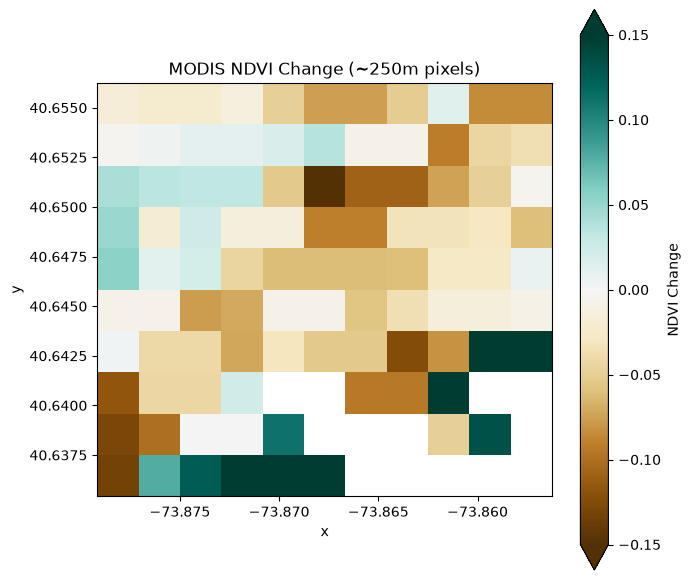

In [24]:
### Plot looks terrible so I took this code from Google AI
### could not figure out how to get the basemap

### add bokeh extension
hvplot.extension('bokeh')

fig, ax = plt.subplots(figsize=(7, 6))

### plot the difference
(
    ndvi_diff.plot.imshow(
        ### which axis is lat and long
        ax=ax,
        cmap='BrBG',  # Brown = loss, White = stable, Green = gain
        vmin=-0.15,  # Tighter symmetric range reveals subtle changes
        vmax=0.15,
        cbar_kwargs={"label": "NDVI Change"},)
        
)

ax.set_aspect("equal")  # Prevents pixels from looking stretched horizontally
ax.set_title("MODIS NDVI Change (~250m pixels)")
plt.tight_layout()
plt.show()

In [15]:
print(ndvi_diff)

<xarray.DataArray 'NDVI' (y: 10, x: 11)> Size: 440B
array([[-0.01744667, -0.02269331, -0.02269331, -0.01297334, -0.04855332,
        -0.07594663, -0.07594663, -0.05137992,  0.01402658, -0.08497339,
        -0.08497339],
       [-0.00294003,  0.00461999,  0.01119332,  0.01119332,  0.01857334,
         0.03666663, -0.0074333 , -0.0074333 , -0.09146667, -0.04449338,
        -0.03715336],
       [ 0.04109341,  0.03465337,  0.03209329,  0.03209329, -0.05363998,
        -0.18281996, -0.10860002, -0.10860002, -0.07457322, -0.04874003,
        -0.00358003],
       [ 0.04889333, -0.01912665,  0.0247733 , -0.0146066 , -0.0146066 ,
        -0.09119993, -0.09037328, -0.03325891, -0.03325891, -0.03001541,
        -0.06030905],
       [ 0.05504668,  0.01187998,  0.02171338, -0.04528666, -0.06132662,
        -0.06132662, -0.06096661, -0.06082672, -0.02799487, -0.02799487,
         0.00742555],
       [-0.00787145, -0.00787145, -0.07687336, -0.07063347, -0.00755829,
        -0.00755829, -0.05669999, -

In [25]:
%store ndvi_da

Stored 'ndvi_da' (Dataset)
